# Análise e seleção do dataset de vazão

Este notebook prepara uma tabela longa com **uma linha por observação diária existente nos Parquets**: `date`, `value_cfs` e `monitoring_location_id`. Ele usa `stations_full.parquet` como seleção oficial das séries/estações e lê somente os Parquets diários locais correspondentes. Não consulta a API nem cria linhas para dias sem registro.

Valores de vazão ausentes que já estejam registrados em um Parquet continuam como `NaN`; zero continua sendo uma observação válida. Assim é possível distinguir zero de valor ausente sem fabricar dias ou medições.

As funções de configuração, catálogo, processamento e visualização ficam nos módulos de `src/`; este notebook serve como interface de execução e análise.

## 1. Carregar os módulos do projeto

Execute as células em ordem. A raiz do projeto é descoberta a partir do notebook aberto.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

def find_project_root(start: Path) -> Path:
    for folder in (start.resolve(), *start.resolve().parents):
        if (folder / "src" / "main.py").is_file() and (folder / "data" / "usgs").is_dir():
            return folder
    raise FileNotFoundError("Não encontrei src/main.py e data/usgs. Abra o notebook na pasta do projeto.")

PROJECT_ROOT = find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import PROCESSED_ROOT, RAW_ROOT, USGS
from src.main import build_analysis_dataset, build_dataset_index, export_dataset
from src.plots import plot_station_series
from src.processing import summarize_station_observations

print(f"Projeto: {PROJECT_ROOT}")
print(f"Parâmetro: {USGS.parameter_code} | estatística: {USGS.statistic_id}")
print(f"Período configurado: {USGS.date_start} a {USGS.date_end}")
print("Fonte: Parquets locais; nenhuma chamada à API será feita nesta análise.")


Projeto: C:\Users\kayla\Meu Drive (kaylany.meneses18@gmail.com)\usgs_dados_streamflow\usgs_streamflow
Parâmetro: 00060 | estatística: 00003
Período configurado: 2010-01-01 a 2024-12-31
Fonte: Parquets locais; nenhuma chamada à API será feita nesta análise.


## 2. Conferir os arquivos de origem

`stations_full.parquet` define quais séries entram na análise. Os Parquets `daily_...parquet` contêm observações; o ID físico da estação vem do catálogo de seleção e não deve ser confundido com `time_series_id`, que identifica uma série.

In [2]:
dataset_index = build_dataset_index()
display(dataset_index.loc[dataset_index["arquivo"].str.contains("stations_full|daily_", regex=True)].head(20))
print(f"Total de Parquets/CSVs indexados em data/: {len(dataset_index):,}")


,arquivo,formato,tamanho_mb
4,data/usgs/processed/stations_full.parquet,parquet,0.246
874,data/usgs/raw/daily_00060_00003_2010-01-01_202...,parquet,0.208
875,data/usgs/raw/daily_00060_00003_2010-01-01_202...,parquet,0.152
876,data/usgs/raw/daily_00060_00003_2010-01-01_202...,parquet,0.281
877,data/usgs/raw/daily_00060_00003_2010-01-01_202...,parquet,0.118
878,data/usgs/raw/daily_00060_00003_2010-01-01_202...,parquet,0.201
879,data/usgs/raw/daily_00060_00003_2010-01-01_202...,parquet,0.328
880,data/usgs/raw/daily_00060_00003_2010-01-01_202...,parquet,0.303
881,data/usgs/raw/daily_00060_00003_2010-01-01_202...,parquet,0.150
882,data/usgs/raw/daily_00060_00003_2010-01-01_202...,parquet,0.337


Total de Parquets/CSVs indexados em data/: 1,026


## 3. Montar a tabela de observações

A função seleciona as séries presentes em `stations_full.parquet`, busca essas séries nos caches diários locais e reduz o resultado às três colunas de análise. Dias sem linha nos arquivos não são inseridos. Datas e vazões não são imputadas.

In [3]:
df_analysis, station_summary = build_analysis_dataset()

print(f"Linhas de observação: {len(df_analysis):,}")
print(f"Estações: {df_analysis['monitoring_location_id'].nunique():,}")
print(f"Datas: {df_analysis['date'].min().date()} a {df_analysis['date'].max().date()}")
print(f"Linhas com vazão NaN já presente nos Parquets: {int(df_analysis['value_cfs'].isna().sum()):,}")
print(f"Observações de vazão zero: {int(df_analysis['value_cfs'].eq(0).sum()):,}")
print("Colunas:", df_analysis.columns.tolist())
display(df_analysis.head(10))


Linhas de observação: 4,310,149
Estações: 991
Datas: 2010-01-01 a 2024-12-31
Linhas com vazão NaN já presente nos Parquets: 851
Observações de vazão zero: 680,878
Colunas: ['date', 'value_cfs', 'monitoring_location_id']


,date,value_cfs,monitoring_location_id
0,2010-01-01,0.0,USGS-09423350
1,2010-01-02,0.0,USGS-09423350
2,2010-01-03,0.0,USGS-09423350
3,2010-01-04,0.0,USGS-09423350
4,2010-01-05,0.0,USGS-09423350
5,2010-01-06,0.0,USGS-09423350
6,2010-01-07,0.0,USGS-09423350
7,2010-01-08,0.0,USGS-09423350
8,2010-01-09,0.0,USGS-09423350
9,2010-01-10,0.0,USGS-09423350


## 4. Avaliar cobertura por estação

Como esta tabela inclui apenas registros existentes nos Parquets, `registros` conta as linhas presentes e o intervalo de datas pode variar por estação. `vazoes_ausentes` conta linhas existentes cujo valor está vazio; não conta dias sem linha no arquivo.

In [4]:
display(station_summary.sort_values("registros", ascending=False).head(20))
display(
    station_summary[["registros", "vazoes_ausentes", "vazoes_zero", "vazoes_validas"]]
    .describe()
)


,monitoring_location_id,registros,primeira_data,ultima_data,vazoes_ausentes,vazoes_zero,vazoes_validas
985,USGS-11532500,5479,2010-01-01,2024-12-31,0,0,5479
0,USGS-09423350,5479,2010-01-01,2024-12-31,0,4571,5479
984,USGS-11530500,5479,2010-01-01,2024-12-31,0,0,5479
983,USGS-11530000,5479,2010-01-01,2024-12-31,0,0,5479
3,USGS-09429100,5479,2010-01-01,2024-12-31,0,0,5479
4,USGS-09429170,5479,2010-01-01,2024-12-31,0,173,5479
5,USGS-09429180,5479,2010-01-01,2024-12-31,0,49,5479
6,USGS-09429190,5479,2010-01-01,2024-12-31,0,187,5479
967,USGS-11521500,5479,2010-01-01,2024-12-31,0,0,5479
966,USGS-11520500,5479,2010-01-01,2024-12-31,0,0,5479


,registros,vazoes_ausentes,vazoes_zero,vazoes_validas
count,991.000000,991.000000,991.000000,991.000000
mean,4349.292634,0.858729,687.061554,4348.433905
std,1717.358824,14.167548,1245.901799,1718.721891
min,3.000000,0.000000,0.000000,0.000000
25%,3251.500000,0.000000,0.000000,3251.500000
50%,5479.000000,0.000000,3.000000,5479.000000
75%,5479.000000,0.000000,748.000000,5479.000000
max,5479.000000,264.000000,5464.000000,5479.000000


## 5. Visualizar uma estação

Altere `STATION_ID` para o identificador USGS desejado. O gráfico mostra somente as observações existentes, portanto intervalos sem linhas não são interpolados.

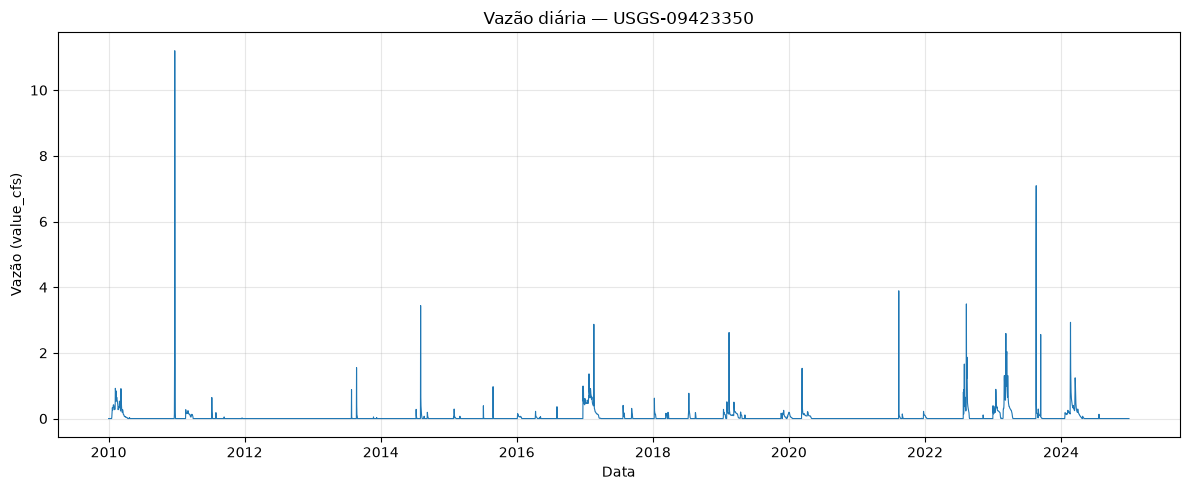

In [5]:
STATION_ID = str(df_analysis["monitoring_location_id"].dropna().iloc[0])
fig, ax = plot_station_series(df_analysis, STATION_ID)
plt.show()
